In [1]:
import torch

import torch.utils.data

import pandas as pd
import scanpy as sc
import squidpy as sq

from pathlib import Path

from gctsvg import visualization
from gctsvg.preprocessing import common, singlecell, st, kidneycancer
from gctsvg.model.ae import STDenoiser, SCDenoiser

/opt/conda/envs/ctSVG/lib/python3.12/site-packages/dask/dataframe/_pyarrow_compat.py:15: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 13.0.0. Please consider upgrading.
  warnings.warn(
/opt/conda/envs/ctSVG/lib/python3.12/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
data_dir = Path('data_repo/Human Kidney Cancer')
patient_id='PD47171'

In [3]:
# read ST data
adata_st = sc.read(data_dir / 'visium_merge_inter_upload.h5ad')
adata_st.var_names_make_unique()

# read scRNA data
adata_sc = sc.read(data_dir / 'RCC_upload_final_raw_counts.h5ad')
adata_sc.var_names_make_unique()

In [4]:
# Extract patient data
adata_st = kidneycancer.extract_st_patient_data(adata_st, patient_id)
adata_sc = kidneycancer.extract_sc_patient_data(adata_sc, patient_id)

# extract cell type information
cell_types, n_classes = singlecell.get_cell_types(adata_sc)

In [5]:
# Format data to use ENSEMBL gene id as index
# necessary to align indexes of st and sc datasets
adata_sc = common.use_ensembl_gene_ids(adata_sc, 'name')

/opt/conda/envs/ctSVG/lib/python3.12/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [6]:
# preprocess st and sc data
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
centroids = singlecell.get_cell_type_centroids(adata_sc, device=device)
common.preprocess(adata_st)
common.preprocess(adata_sc)

In [7]:
st_hvg = adata_st.var['highly_variable'].index
sc_hvg = adata_sc.var['highly_variable'].index

In [8]:
geneset = st_hvg.intersection(sc_hvg)
geneset

Index(['ENSG00000225880', 'ENSG00000230368', 'ENSG00000187634',
       'ENSG00000188976', 'ENSG00000187961', 'ENSG00000187583',
       'ENSG00000187642', 'ENSG00000188290', 'ENSG00000187608',
       'ENSG00000188157',
       ...
       'ENSG00000198712', 'ENSG00000228253', 'ENSG00000198899',
       'ENSG00000198938', 'ENSG00000198840', 'ENSG00000212907',
       'ENSG00000198886', 'ENSG00000198786', 'ENSG00000198695',
       'ENSG00000198727'],
      dtype='object', name='ENSEMBL', length=15942)

In [9]:
# get feature matrices from st and sc data
geneset = common.get_common_geneset(adata_st, adata_sc)
adata_st = adata_st[:, geneset]
adata_sc = adata_sc[:, geneset]

n_feats = len(geneset)


X_st = common.get_feature_matrix(adata_st)
dataset_sc = singlecell.create_denoiser_dataset(adata_sc, device=device)
dtype=dataset_sc[0][0].dtype



# build graph from st adjacency
dataset_st = st.create_graph_data(adata_st, device=device)

Number of overlap genes: 896
<class 'numpy.ndarray'>


In [10]:
n_code_sc = 200
n_code_st = 200

num_epochs=1
batch_size=4096

In [11]:
sc_denoiser = SCDenoiser(n_feats, n_code_sc, device=device, dtype=dtype)

5 tensor([896, 722, 548, 374, 200], dtype=torch.int32)
5 tensor([200, 374, 548, 722, 896], dtype=torch.int32)
AutoEncoder(
  (encoder): FFN(
    (backbone_fc): Sequential(
      (0): Dropout(p=0.2, inplace=False)
      (1): Linear(in_features=896, out_features=722, bias=True)
      (2): BatchNorm1d(722, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (3): PReLU(num_parameters=722)
      (4): Dropout(p=0.2, inplace=False)
      (5): Linear(in_features=722, out_features=548, bias=True)
      (6): BatchNorm1d(548, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (7): PReLU(num_parameters=548)
      (8): Dropout(p=0.2, inplace=False)
      (9): Linear(in_features=548, out_features=374, bias=True)
      (10): BatchNorm1d(374, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (11): PReLU(num_parameters=374)
    )
    (out_fc): Sequential(
      (0): Dropout(p=0.2, inplace=False)
      (1): Linear(in_features=374, out_features=200

In [12]:
code, reconstruction, sc_total_losses = sc_denoiser.fit_denoise(dataset_sc, num_epochs, batch_size)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

In [13]:
dataset_sc[0][0].shape

torch.Size([896])

In [14]:
dataset_sc[0][0].shape

torch.Size([896])

In [15]:
len(dataset_sc)

36110

In [16]:
import torch.nn.functional as F
from torch.utils.data import DataLoader

loader = DataLoader(dataset_sc, batch_size=len(dataset_sc))
batch = next(iter(loader))
loss = F.mse_loss(reconstruction, batch[0].cpu(), reduction='mean')
loss.detach().numpy()
# 5 layers, 0.1 dropout: 0.1100 -> reduction ratio = -0.1
# 5 layers, 0.2 dropout: 0.1717 -> reduction ratio = 0.1415

array(0.59326039)

In [17]:
reconstruction[:,-1]

tensor([0.3786, 0.3969, 0.3542,  ..., 3.9303, 3.2563, 1.4427],
       dtype=torch.float64)

In [18]:
batch[0].mean(), batch[0].var()

(tensor(0.2347, device='cuda:0', dtype=torch.float64),
 tensor(0.7884, device='cuda:0', dtype=torch.float64))

In [19]:
reconstruction[0].mean(), reconstruction[0].var()

(tensor(0.0933, dtype=torch.float64), tensor(0.0318, dtype=torch.float64))

In [20]:
reconstruction[:,-2:]

tensor([[0.5246, 0.3786],
        [0.5711, 0.3969],
        [0.4791, 0.3542],
        ...,
        [4.6966, 3.9303],
        [3.9284, 3.2563],
        [1.7688, 1.4427]], dtype=torch.float64)

In [21]:
batch[0][:,-2:]

tensor([[5.2305, 3.2130],
        [4.1501, 1.6143],
        [3.0625, 1.6648],
        ...,
        [6.4700, 3.7392],
        [5.3727, 2.8903],
        [0.0000, 0.0000]], device='cuda:0', dtype=torch.float64)

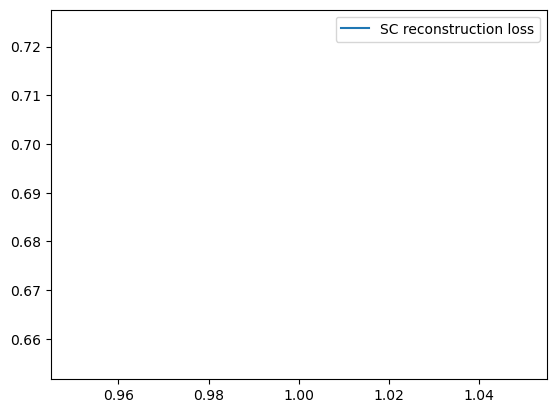

In [22]:
visualization.show_training_curve(range(1,num_epochs + 1), [sc_total_losses], ["SC reconstruction loss"])

In [23]:
num_epochs=800

In [24]:
st_denoiser = STDenoiser(n_feats, n_code_sc, device=device, dtype=dtype)

GCN(896, 200, num_layers=2)
GCN(200, 896, num_layers=2)
DeepGraphInfomax(200)
GCNDGIAE(
  (encoder): GCN(896, 200, num_layers=2)
  (decoder): GCN(200, 896, num_layers=2)
  (DGI): DeepGraphInfomax(200)
)


In [25]:
code, reconstruction, st_total_losses, reconstruction_losses, contrastive_losses = st_denoiser.fit_denoise(dataset_st, num_epochs)

  0%|          | 0/800 [00:00<?, ?it/s]

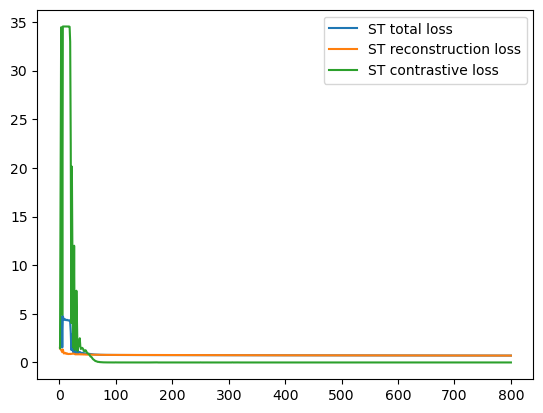

In [26]:
visualization.show_training_curve(range(1,num_epochs + 1), [st_total_losses, reconstruction_losses, contrastive_losses], ["ST total loss", "ST reconstruction loss", "ST contrastive loss"])

In [27]:
x = dataset_st.x.cpu()
loss = F.mse_loss(reconstruction, x, reduction='mean')
loss.detach().numpy()

array(0.70680881)

In [28]:
1 - loss.detach().numpy()/0.2

-2.534044048176668